# Лабораторная работа № 1

## Задание

1. Реализовать функцию генерации временного ряда.
2. Обеспечить фиксированный временной интервал между точками: 5 минут.
3. Реализовать возможность задания количества точек:
    * по умолчанию: 1000.
4. Реализовать варианты дисперсии:
    * постоянная;
    * растущая;
    * убывающая.
5. Реализовать варианты тренда:
    * отсутствует;
    * быстрый рост;
    * медленный рост;
    * быстрое убывание;
    * медленное убывание.
6. Реализовать варианты сезонности:
    * отсутствует;
    * одна сезонность;
    * две накладывающихся сезонности.
7. Обеспечить корректную работу кода в Jupyter Notebook.
8. Реализовать сохранение результата в CSV-файл.
9. Реализовать сохранение графика в PNG-файл.
10. Сформировать 3 отчётных изображения с различными параметрами временного ряда

## Дополнительно

1. Добавить нелинейный тренд:
    * экспоненциальный;
    * полиномиальный;
    * логарифмический.
2. Добавить выбросы.
3. Добавить пропуски во временном ряде.
4. Добавить сохранение метаданных генерации в отдельный JSON-файл.

## Библиотеки

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from datetime import date, datetime, timedelta, time

## Реализация

### Генератор ряда

Генерирует временной ряд со случайными параметрами без использования Pandas

#### Параметры:

* n_points : int
    - Количество точек данных
* deviation: str
    - Тип дисперсии: const, grow, decay, random
* trend_speed: str
    - Режим тренда: none, fast_up, slow_up, fast_down, slow_down, random
* trend_type: str
    - Тип тренда: linear, exponential, quadratic, logarithmic, random
* seasonality: str
    - Режимы сезонности: none, one, two, random
* outliers: int
    - Количество выбросов
* gaps: int
    - Количество пропусков
* seed : int или None
    - Seed для воспроизводимости

#### Возвращает:

* tuple: (dates, values) где dates - список строк дат, values - список значений

In [2]:
def _get_params(parameters):  # чтение параметров
    try:
        n_points = parameters["n_points"]
    except KeyError:
        n_points = 1000

    try:
        deviation = parameters["deviation"]
    except KeyError:
        deviation = "random"

    try:
        trend_speed = parameters["trend_speed"]
    except KeyError:
        trend_speed = "random"

    try:
        trend_type = parameters["trend_type"]
    except KeyError:
        trend_type = "random"

    try:
        seasonality = parameters["seasonality"]
    except KeyError:
        seasonality = "random"

    try:
        outliers = parameters["outliers"]
    except KeyError:
        outliers = 0

    try:
        gaps = parameters["gaps"]
    except KeyError:
        gaps = 0

    try:
        seed = parameters["seed"]
    except KeyError:
        seed = None

    return n_points, deviation, trend_speed, trend_type, seasonality, outliers, gaps, seed

In [3]:
def generate_time_series(parameters = {}):    
    n_points, deviation, trend_speed, trend_type, seasonality, outliers, gaps, seed = _get_params(parameters)

    if seed is not None:
        np.random.seed(seed)

    x = np.arange(n_points)
        
    # Генерируем временные метки (каждые 5 мин, начиная с 00:00 сегодняшнего дня)
    
    start_date = datetime.combine(date.today(), time())
    dates = [(start_date + timedelta(minutes=5*i)) for i in range(n_points)]

    # Задаём шум через его стандартное отклонение
    
    deviation_types = ["const", "grow", "decay"]
    
    base_deviation = 10  # начальное отклонение
    scale_deviation = base_deviation / n_points  # скорость роста отклонения

    if deviation == "random":
        deviation = np.random.choice(deviation_types)

    noise = np.zeros(n_points, dtype=np.float64)
    
    match deviation:
        case "const":
            noise = np.random.normal(0, base_deviation, n_points)

        case "grow":
            for i in range(n_points):
                noise[i] = np.random.normal(0, base_deviation + scale_deviation*i)

        case "decay":
             for i in range(n_points):
                noise[i] = np.random.normal(0, 2*base_deviation - scale_deviation*i)           
            
    # Генерируем тренд

    trend_component = np.zeros(n_points, dtype=np.float64)

    trend_speeds = ["none", "fast_up", "slow_up", "fast_down", "slow_down"]

    if trend_speed == "random":
        trend_speed = np.random.choice(trend_speeds)

    trend_types = ["linear", "exponential", "quadratic", "logarithmic"]

    if trend_type == "random":
        trend_type = np.random.choice(trend_types)

    if trend_speed != "none":
        lin_slope, exp_scale, exp_pow, quad_a, quad_b, log_scale = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

        if trend_speed == "fast_up" or trend_speed == "fast_down":
            lin_slope = np.random.uniform(0.4, 1.0)
            exp_scale = np.random.uniform(0.5, 1.0)
            exp_pow = np.random.uniform(5/n_points, 7/n_points)
            quad_a = np.random.uniform(0.0001, 0.0005)
            quad_b = np.random.uniform(0.2, 0.5)
            log_scale = np.random.uniform(50, 80)

            if trend_speed == "fast_down":
                lin_slope, exp_scale, quad_a, quad_b, log_scale = -lin_slope, -exp_scale, -quad_a, -quad_b, -log_scale

        elif trend_speed == "slow_up" or trend_speed == "slow_down":
            lin_slope = np.random.uniform(0.1, 0.2)
            exp_scale = np.random.uniform(0.5, 1.0)
            exp_pow = np.random.uniform(3/n_points, 4/n_points)
            quad_a = np.random.uniform(0.00001, 0.00005)
            quad_b = np.random.uniform(0.1, 0.2)
            log_scale = np.random.uniform(10, 20)

            if trend_speed == "slow_down":
                lin_slope, exp_scale, quad_a, quad_b, log_scale = -lin_slope, -exp_scale, -quad_a, -quad_b, -log_scale

        initial_trend = np.random.uniform(50, 100) # случайное начальное значение
        
        match trend_type:
            case "linear":  # линейный тренд: y = mx + b
                trend_component = lin_slope * x + initial_trend
    
            case "exponential":  # экспоненциальный тренд: y = a*exp(bx) + c
                trend_component = exp_scale * np.exp(exp_pow * x) + initial_trend

            case "quadratic":  # квадратичный тренд: y = ax^2 + bx + c
                trend_component = quad_a * x**2 + quad_b * x + initial_trend

            case "logarithmic":  # логарифмический тренд: y = a*log(x+1) + b
                trend_component = log_scale * np.log(x + 1) + initial_trend

    # Генерируем сезонность

    seasonal_component = np.zeros(n_points, dtype=np.float64)

    seasonality_types = ["none", "one", "two"]

    if seasonality == "random":
        seasonality = np.random.choice(seasonality_types)

    if seasonality == "one" or seasonality == "two":  # первая сезонная компонента
        amplitude = np.random.uniform(10, 30) # амплитуда
        period = 12 # количество точек в периоде
        phase = np.random.uniform(0, 2*np.pi) # фаза

        seasonal_component += amplitude * np.sin(2*np.pi*x/period + phase)  # синусоида

    if seasonality == "two":  # вторая сезонная компонента
        amplitude = np.random.uniform(20, 40) # амплитуда
        period = 72 # количество точек в периоде
        phase = np.random.uniform(0, 2*np.pi) # фаза

        seasonal_component += amplitude * np.sin(2*np.pi*x/period + phase)  # синусоида
        
    # Комбинируем все компоненты
    
    values = noise + trend_component + seasonal_component

    # Добавляем выбросы
    # Выброс - это всё, что либо меньше Q25 - 1.5 * (Q75 - Q25), либо больше Q75 + 1.5 * (Q75 - Q25)
    
    Q75 = np.percentile(values, 75)
    Q25 = np.percentile(values, 25)
    IQR = Q75 - Q25

    outliers_index = np.random.choice(x, outliers)

    for i in outliers_index:
        IQR_scale = np.random.uniform(1.6, 3.0)
        outlier_rng = np.random.uniform(0, 1)

        if outlier_rng <= 0.5:
            values[i] = Q25 - IQR_scale * IQR

        else:
            values[i] = Q75 + IQR_scale * IQR

    # Добавляем пропуски

    gaps_index = np.random.choice(x, gaps)
    values[gaps_index] = np.nan
    
    return dates, values

### Сохранение в виде CSV

In [4]:
def save_csv(dates, values):
    timestamp = datetime.now().strftime("ts_%Y%m%d_%H%M%S")
    path = Path(f"{timestamp}.csv")
    n = 1

    while True:
        try:
            with path.open("x", encoding="utf-8") as file:
                break

        except FileExistsError:
            path = Path(f"{timestamp}_{n}.csv")
            n += 1

    with path.open(mode="w", encoding="utf-8") as file:
        file.write("timestamp,value\n")

        for date, value in zip(dates, values):
            file.write(f"{date},{value}\n")

### Сохранение метаданных в JSON

In [5]:
def save_meta(parameters, filename):
    with open(filename, mode="w", encoding="utf-8") as file:
        json.dump(parameters, file)

### Чтение метаданных из JSON

In [6]:
def read_meta(filename):
    with open(filename, mode="r", encoding="utf-8") as file:
        return json.load(file)

### Отрисовка и сохранение в PNG

In [7]:
def plot_time_series(dates, values, figsize=(14, 6), filename=None):        
    plt.figure(figsize=figsize)
    
    plt.plot(dates, values, label='Временной ряд', color='blue', linewidth=1.5)
    plt.title('Сгенерированный временной ряд', fontsize=16, fontweight='bold')
    plt.xlabel('Дата и время', fontsize=12)
    plt.ylabel('Значение', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Автоматически форматируем ось X для дат
    plt.gcf().autofmt_xdate()

    if filename is not None:
        plt.savefig(filename)
    
    plt.show()

### Запуски 

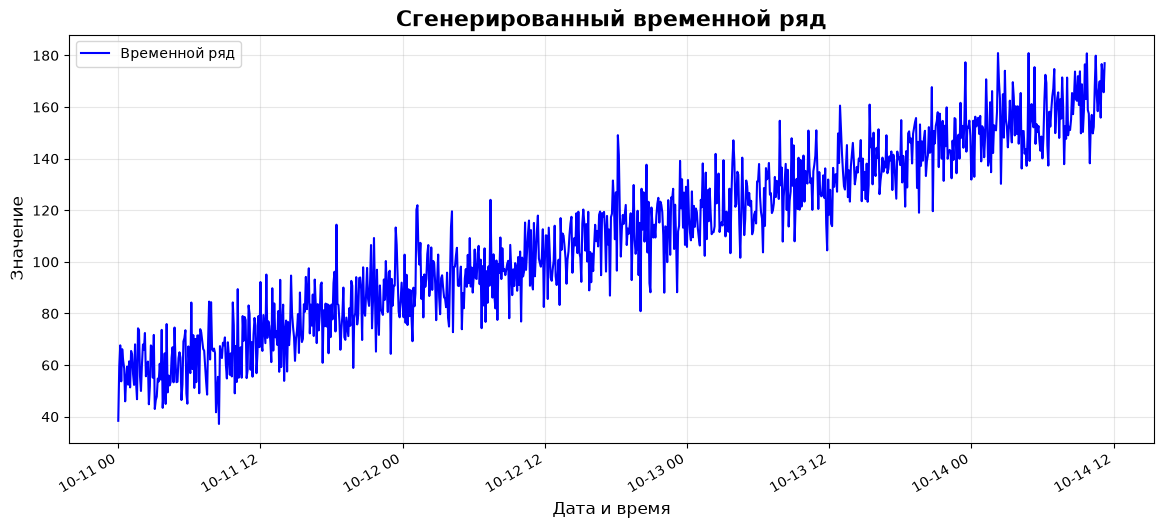

In [8]:
parameters = {"deviation": "const", "trend_speed": "slow_up", "trend_type": "linear", "seasonality": "none", "seed": 100}
dates, values = generate_time_series(parameters)
plot_time_series(dates, values)

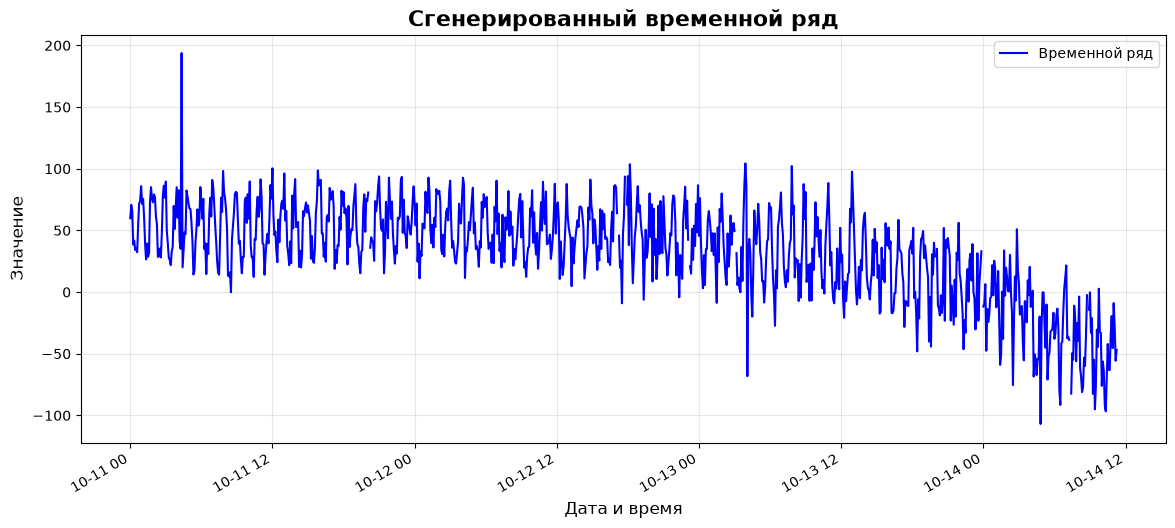

In [9]:
parameters = {"deviation": "grow", "trend_speed": "fast_down", "trend_type": "exponential", "seasonality": "one", "outliers": 3, "gaps": 10, "seed": 100}
dates, values = generate_time_series(parameters)
plot_time_series(dates, values, filename="images/lab_image_1.png")

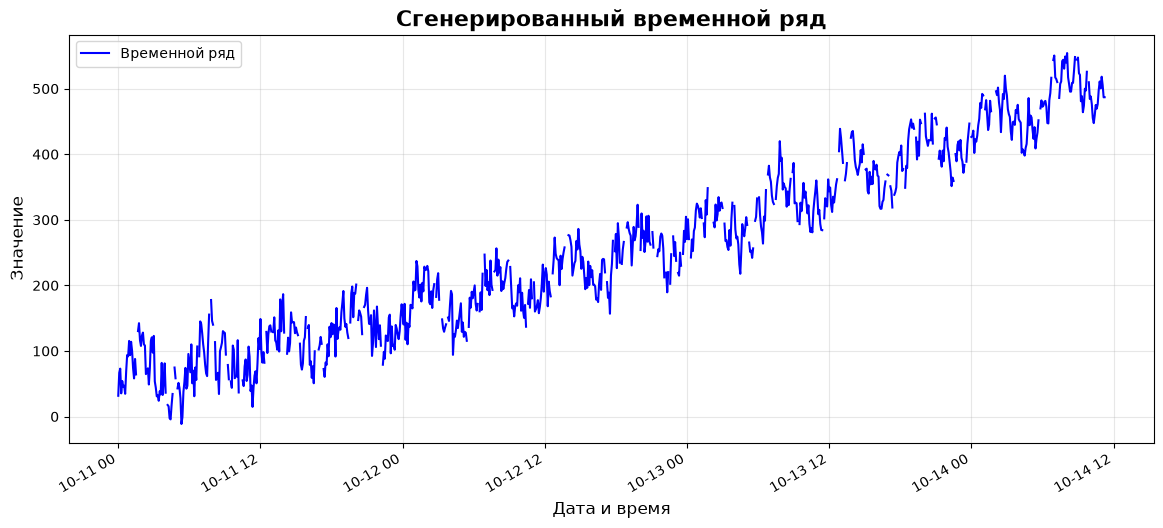

In [10]:
parameters = {"deviation": "decay", "trend_speed": "fast_up", "trend_type": "quadratic", "seasonality": "two", "gaps": 100, "seed": 100}
dates, values = generate_time_series(parameters)
plot_time_series(dates, values, filename="images/lab_image_2.png")

In [11]:
parameters = {"deviation": "const", "trend_speed": "slow_up", "trend_type": "logarithmic", "seasonality": "one", "outliers": 1, "seed": 100}
dates, values = generate_time_series(parameters)

Проверка сохранения в CSV

In [12]:
save_csv(dates, values)

Проверка сохранения в JSON

In [13]:
save_meta(parameters, "metadata.json")

Проверка чтения JSON

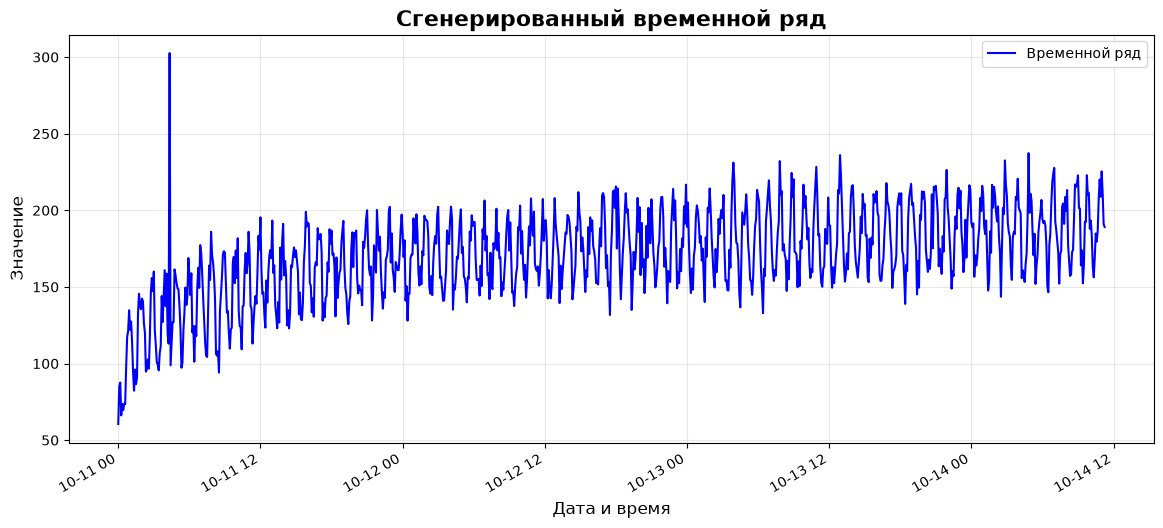

In [14]:
read_params = read_meta("metadata.json")
dates, values = generate_time_series(read_params)
plot_time_series(dates, values, filename="images/lab_image_3.png")